In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 

# multi indekslash

* hierachichal indeks

# hierachichal indeksli malumotlar odatda bizga katta malumotlarni indekslashda ishlatamiz
* bunga hali misollar yozamiz keling hozir oddiy indekslashni kuraylik

In [2]:
data = pd.Series(np.random.randn(9), index=['a','b','c','d','f','h','g','i','y'])

In [3]:
data

a    0.995448
b    0.524279
c    0.022019
d    0.537434
f   -0.276817
h   -1.147353
g    2.050142
i   -0.306948
y   -0.037925
dtype: float64

In [4]:
data.index

Index(['a', 'b', 'c', 'd', 'f', 'h', 'g', 'i', 'y'], dtype='object')

In [6]:
data_irarxik = pd.Series(np.random.randn(9), 
                         index=[['a','a','c','c','c','h','g','i','i'],[1,2,3,4,5,6,7,8,9]])
data_irarxik


a  1   -0.430416
   2    0.206906
c  3    1.430782
   4   -0.816493
   5    1.508838
h  6   -1.532592
g  7   -1.795236
i  8    1.722047
   9   -0.681996
dtype: float64

# mana endi datamiz multi index

In [7]:
data_irarxik.index

MultiIndex([('a', 1),
            ('a', 2),
            ('c', 3),
            ('c', 4),
            ('c', 5),
            ('h', 6),
            ('g', 7),
            ('i', 8),
            ('i', 9)],
           )

# irarxik malumotlarni ajratib olish.

# endi biz 1ta 'a' ni choqirish orqali 2ta indekslangan qiymat olishimiz mumkin

In [8]:
data_irarxik['a'] # subsetlari (indekslari) bilan ajratib oladi

1   -0.430416
2    0.206906
dtype: float64

* mana korib turganingizdek ajayib korinishda multi indekslash ishladi

In [10]:
data_irarxik.loc[:, 2] # bu barcha 2chi indeksladi malumotlarni chiqaradi hozircha 1ta

a    0.206906
dtype: float64

In [19]:
data_irarxik.iloc[1]

0.20690572206367705

# stack va unstack

# irarxik malumotlarni unstack yordamida yigsak buladi yani sochilgan malumotlarni df korinishida chiqorlsak buladi

In [20]:
data_irarxik.unstack()

,1,2,3,4,5,6,7,8,9
a,-0.430416,0.206906,NaN,NaN,NaN,NaN,NaN,NaN,NaN
c,NaN,NaN,1.430782,-0.816493,1.508838,NaN,NaN,NaN,NaN
g,NaN,NaN,NaN,NaN,NaN,NaN,-1.795236,NaN,NaN
h,NaN,NaN,NaN,NaN,NaN,-1.532592,NaN,NaN,NaN
i,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.722047,-0.681996


# endi bu df kornishidan asil kornishiga qaytarish uchun stack usulidan foydalanishimiz mumki ekan

In [21]:
data_irarxik.unstack().stack()


a  1   -0.430416
   2    0.206906
c  3    1.430782
   4   -0.816493
   5    1.508838
g  7   -1.795236
h  6   -1.532592
i  8    1.722047
   9   -0.681996
dtype: float64

# mana korib turganingizdek bizga datamiz yana seiesga utib qoldi unstackni sax qimaganim uchun yana choqirdim

# dunyo shaharlarining havo va suv sifati malumotlari ustida amallar bajarish

In [22]:
df = pd.read_csv("world_cities_air_water_quality.csv")

In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3963 entries, 0 to 3962
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   City               3963 non-null   object 
 1    "Region"          3963 non-null   object 
 2    "Country"         3963 non-null   object 
 3    "AirQuality"      3963 non-null   float64
 4    "WaterPollution"  3963 non-null   float64
dtypes: float64(2), object(3)
memory usage: 154.9+ KB


In [24]:
df.head()

,City,"""Region""","""Country""","""AirQuality""","""WaterPollution"""
0,New York City,"""New York""","""United States of America""",46.816038,49.504950
1,"Washington, D.C.","""District of Columbia""","""United States of America""",66.129032,49.107143
2,San Francisco,"""California""","""United States of America""",60.514019,43.000000
3,Berlin,"""""","""Germany""",62.364130,28.612717
4,Los Angeles,"""California""","""United States of America""",36.621622,61.299435


In [25]:
colums = ['City',	"Region",	"Country"	,"AirQuality",	"WaterPollution"]
df.columns = colums

In [26]:
df.head()

,City,Region,Country,AirQuality,WaterPollution
0,New York City,"""New York""","""United States of America""",46.816038,49.504950
1,"Washington, D.C.","""District of Columbia""","""United States of America""",66.129032,49.107143
2,San Francisco,"""California""","""United States of America""",60.514019,43.000000
3,Berlin,"""""","""Germany""",62.364130,28.612717
4,Los Angeles,"""California""","""United States of America""",36.621622,61.299435


In [27]:
df["Region"] = df["Region"].map(lambda x: x.replace('"',''))
df

,City,Region,Country,AirQuality,WaterPollution
0,New York City,New York,"""United States of America""",46.816038,49.504950
1,"Washington, D.C.",District of Columbia,"""United States of America""",66.129032,49.107143
2,San Francisco,California,"""United States of America""",60.514019,43.000000
3,Berlin,,"""Germany""",62.364130,28.612717
4,Los Angeles,California,"""United States of America""",36.621622,61.299435
...,...,...,...,...,...
3958,Yanbu,Medina Province,"""Saudi Arabia""",0.000000,50.000000
3959,Cordoba,Andalusia,"""Spain""",85.714286,8.333333
3960,Vic,Catalonia,"""Spain""",100.000000,0.000000
3961,Segovia,Castile and Leon,"""Spain""",100.000000,0.000000


In [28]:
df["Country"] = df["Country"].map(lambda x: x.replace('"',''))

In [29]:
df

,City,Region,Country,AirQuality,WaterPollution
0,New York City,New York,United States of America,46.816038,49.504950
1,"Washington, D.C.",District of Columbia,United States of America,66.129032,49.107143
2,San Francisco,California,United States of America,60.514019,43.000000
3,Berlin,,Germany,62.364130,28.612717
4,Los Angeles,California,United States of America,36.621622,61.299435
...,...,...,...,...,...
3958,Yanbu,Medina Province,Saudi Arabia,0.000000,50.000000
3959,Cordoba,Andalusia,Spain,85.714286,8.333333
3960,Vic,Catalonia,Spain,100.000000,0.000000
3961,Segovia,Castile and Leon,Spain,100.000000,0.000000


In [30]:
df["Country"] = df["Country"].map(lambda x: x.strip())

In [31]:
df["Region"] = df["Region"].map(lambda x: x.strip())


In [32]:
df

,City,Region,Country,AirQuality,WaterPollution
0,New York City,New York,United States of America,46.816038,49.504950
1,"Washington, D.C.",District of Columbia,United States of America,66.129032,49.107143
2,San Francisco,California,United States of America,60.514019,43.000000
3,Berlin,,Germany,62.364130,28.612717
4,Los Angeles,California,United States of America,36.621622,61.299435
...,...,...,...,...,...
3958,Yanbu,Medina Province,Saudi Arabia,0.000000,50.000000
3959,Cordoba,Andalusia,Spain,85.714286,8.333333
3960,Vic,Catalonia,Spain,100.000000,0.000000
3961,Segovia,Castile and Leon,Spain,100.000000,0.000000


In [33]:
df[df["Country"]=="Germany"]

,City,Region,Country,AirQuality,WaterPollution
3,Berlin,,Germany,62.364130,28.612717
28,Cologne,North Rhine-Westphalia,Germany,60.714286,27.777778
40,Bonn,North Rhine-Westphalia,Germany,82.812500,22.500000
52,Heilbronn,Baden-Wurttemberg,Germany,80.000000,0.000000
76,Aachen,North Rhine-Westphalia,Germany,70.454545,17.857143
...,...,...,...,...,...
2693,Bad Waldsee,Baden-Wurttemberg,Germany,100.000000,50.000000
2714,Weilheim in Oberbayern,Bavaria,Germany,100.000000,50.000000
2727,Buckow,Brandenburg,Germany,87.500000,50.000000
3942,Erfurt,Thuringia,Germany,85.000000,50.000000


# Pivot_table orqali irarxik indekslash

In [34]:
df

,City,Region,Country,AirQuality,WaterPollution
0,New York City,New York,United States of America,46.816038,49.504950
1,"Washington, D.C.",District of Columbia,United States of America,66.129032,49.107143
2,San Francisco,California,United States of America,60.514019,43.000000
3,Berlin,,Germany,62.364130,28.612717
4,Los Angeles,California,United States of America,36.621622,61.299435
...,...,...,...,...,...
3958,Yanbu,Medina Province,Saudi Arabia,0.000000,50.000000
3959,Cordoba,Andalusia,Spain,85.714286,8.333333
3960,Vic,Catalonia,Spain,100.000000,0.000000
3961,Segovia,Castile and Leon,Spain,100.000000,0.000000


In [35]:
df1 = pd.pivot_table(df, index=["Country", "City"])

/var/folders/5r/8qsc7qzj04g73js6m7szr_7h0000gn/T/ipykernel_29643/2842639430.py:1: FutureWarning: pivot_table dropped a column because it failed to aggregate. This behavior is deprecated and will raise in a future version of pandas. Select only the columns that can be aggregated.
  df1 = pd.pivot_table(df, index=["Country", "City"])


In [38]:
df1

AirQuality  WaterPollution
Country     City                                
Afghanistan Andkhoy    50.000000       50.000000
            Farah     100.000000        0.000000
            Herat      43.750000       31.250000
            Kabul      18.421053       81.060606
            Kandahar    0.000000       75.000000
...                          ...             ...
Zambia      Mansa      75.000000       25.000000
Zimbabwe    Bindura    50.000000       75.000000
            Bulawayo   67.857143       71.428571
            Harare     38.461538       87.500000
            Masvingo   25.000000       62.500000

[3895 rows x 2 columns]

In [39]:
df1.index

MultiIndex([('Afghanistan',        'Andkhoy'),
            ('Afghanistan',          'Farah'),
            ('Afghanistan',          'Herat'),
            ('Afghanistan',          'Kabul'),
            ('Afghanistan',       'Kandahar'),
            ('Afghanistan', 'Mazar-i-Sharif'),
            (    'Albania',         'Ballsh'),
            (    'Albania',         'Burrel'),
            (    'Albania',         'Durres'),
            (    'Albania',        'Elbasan'),
            ...
            (      'Yemen',          'Sanaa'),
            (      'Yemen',         'Ta'izz'),
            (     'Zambia',       'Chingola'),
            (     'Zambia',          'Kitwe'),
            (     'Zambia',         'Lusaka'),
            (     'Zambia',          'Mansa'),
            (   'Zimbabwe',        'Bindura'),
            (   'Zimbabwe',       'Bulawayo'),
            (   'Zimbabwe',         'Harare'),
            (   'Zimbabwe',       'Masvingo')],
           names=['Country', 'City'], lengt

# endi har bir davlat indekga aylandi va ular ichidagi shaharlar qiymat bulib qoldi bu esa Multi indekslash deb ataladi

In [41]:
df1.loc[["Germany","Uzbekistan"]]

AirQuality  WaterPollution
Country    City                                         
Germany    Aachen              70.454545       17.857143
           Aalen               87.500000       50.000000
           Abensberg          100.000000       50.000000
           Amberg             100.000000       50.000000
           Annaberg-Buchholz   87.500000       50.000000
...                                  ...             ...
           Wolfsburg           96.875000        0.000000
           Worms               60.000000      100.000000
           Wuppertal           90.000000        0.000000
           Zwickau             75.000000       50.000000
Uzbekistan Tashkent            56.451613       49.166667

[125 rows x 2 columns]

# irarxik ustunlarda malumotlar toplami

* ustunlarni irarxik korinishga keltirish

In [42]:
df2 = df1.copy()

In [43]:
df2["AirPollution"] = 100-df2["AirQuality"]
df2

AirQuality  WaterPollution  AirPollution
Country     City                                              
Afghanistan Andkhoy    50.000000       50.000000     50.000000
            Farah     100.000000        0.000000      0.000000
            Herat      43.750000       31.250000     56.250000
            Kabul      18.421053       81.060606     81.578947
            Kandahar    0.000000       75.000000    100.000000
...                          ...             ...           ...
Zambia      Mansa      75.000000       25.000000     25.000000
Zimbabwe    Bindura    50.000000       75.000000     50.000000
            Bulawayo   67.857143       71.428571     32.142857
            Harare     38.461538       87.500000     61.538462
            Masvingo   25.000000       62.500000     75.000000

[3895 rows x 3 columns]

In [44]:
df2["waterquality"] = 100-df2["WaterPollution"]
df2

AirQuality  WaterPollution  AirPollution  waterquality
Country     City                                                            
Afghanistan Andkhoy    50.000000       50.000000     50.000000     50.000000
            Farah     100.000000        0.000000      0.000000    100.000000
            Herat      43.750000       31.250000     56.250000     68.750000
            Kabul      18.421053       81.060606     81.578947     18.939394
            Kandahar    0.000000       75.000000    100.000000     25.000000
...                          ...             ...           ...           ...
Zambia      Mansa      75.000000       25.000000     25.000000     75.000000
Zimbabwe    Bindura    50.000000       75.000000     50.000000     25.000000
            Bulawayo   67.857143       71.428571     32.142857     28.571429
            Harare     38.461538       87.500000     61.538462     12.500000
            Masvingo   25.000000       62.500000     75.000000     37.500000

[3895 rows x 4 columns]

In [45]:
df3 = pd.DataFrame(df2.values, index=df2.index, columns = [['AIR','AIR', 'Water','Water'], ['AirQuality',	'WaterPollution',	'AirPollution',	'waterquality']])

In [47]:
df3

AIR                       Water             
                      AirQuality WaterPollution AirPollution waterquality
Country     City                                                         
Afghanistan Andkhoy    50.000000      50.000000    50.000000    50.000000
            Farah     100.000000       0.000000     0.000000   100.000000
            Herat      43.750000      31.250000    56.250000    68.750000
            Kabul      18.421053      81.060606    81.578947    18.939394
            Kandahar    0.000000      75.000000   100.000000    25.000000
...                          ...            ...          ...          ...
Zambia      Mansa      75.000000      25.000000    25.000000    75.000000
Zimbabwe    Bindura    50.000000      75.000000    50.000000    25.000000
            Bulawayo   67.857143      71.428571    32.142857    28.571429
            Harare     38.461538      87.500000    61.538462    12.500000
            Masvingo   25.000000      62.500000    75.000000    37.500000

[3895 rows x 4 columns]

# endi biz ham indeksni irarxikga va columnsni ham irarxikga utgazdik

In [70]:
df

,City,Region,Country,AirQuality,WaterPollution
0,New York City,New York,United States of America,46.816038,49.504950
1,"Washington, D.C.",District of Columbia,United States of America,66.129032,49.107143
2,San Francisco,California,United States of America,60.514019,43.000000
3,Berlin,,Germany,62.364130,28.612717
4,Los Angeles,California,United States of America,36.621622,61.299435
...,...,...,...,...,...
3958,Yanbu,Medina Province,Saudi Arabia,0.000000,50.000000
3959,Cordoba,Andalusia,Spain,85.714286,8.333333
3960,Vic,Catalonia,Spain,100.000000,0.000000
3961,Segovia,Castile and Leon,Spain,100.000000,0.000000


(array([[ 307.,  154.,  304.,  245.,  178.,  430.,  353.,  568.,  493.,
          863.],
        [ 488.,  167.,  432.,  377.,  252., 1275.,  241.,  369.,   84.,
          210.]]),
 array([  0.,  10.,  20.,  30.,  40.,  50.,  60.,  70.,  80.,  90., 100.]),
 <a list of 2 BarContainer objects>)

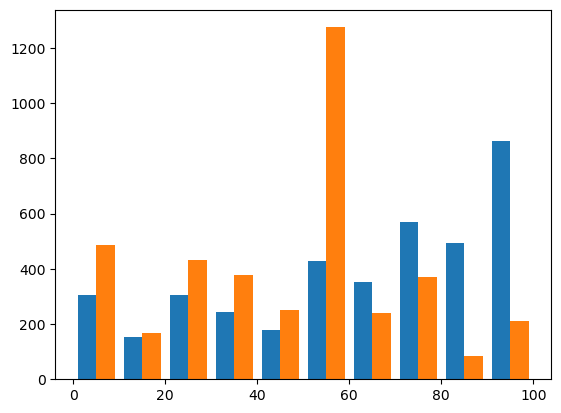

In [53]:
plt.hist(df3["AIR"])

In [54]:
df3["AIR"]

AirQuality  WaterPollution
Country     City                                
Afghanistan Andkhoy    50.000000       50.000000
            Farah     100.000000        0.000000
            Herat      43.750000       31.250000
            Kabul      18.421053       81.060606
            Kandahar    0.000000       75.000000
...                          ...             ...
Zambia      Mansa      75.000000       25.000000
Zimbabwe    Bindura    50.000000       75.000000
            Bulawayo   67.857143       71.428571
            Harare     38.461538       87.500000
            Masvingo   25.000000       62.500000

[3895 rows x 2 columns]

In [55]:
df3.columns.names = ['Object','Info']

In [56]:
df3

Object                       AIR                       Water             
Info                  AirQuality WaterPollution AirPollution waterquality
Country     City                                                         
Afghanistan Andkhoy    50.000000      50.000000    50.000000    50.000000
            Farah     100.000000       0.000000     0.000000   100.000000
            Herat      43.750000      31.250000    56.250000    68.750000
            Kabul      18.421053      81.060606    81.578947    18.939394
            Kandahar    0.000000      75.000000   100.000000    25.000000
...                          ...            ...          ...          ...
Zambia      Mansa      75.000000      25.000000    25.000000    75.000000
Zimbabwe    Bindura    50.000000      75.000000    50.000000    25.000000
            Bulawayo   67.857143      71.428571    32.142857    28.571429
            Harare     38.461538      87.500000    61.538462    12.500000
            Masvingo   25.000000      62.500000    75.000000    37.500000

[3895 rows x 4 columns]

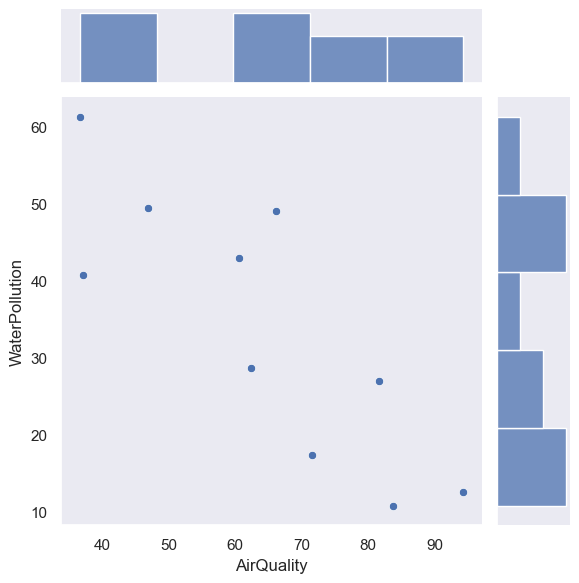

In [84]:
# plt.pie(df3["AIR"],df3["Water"])
sns.jointplot(x=df["AirQuality"][:10],y=df["WaterPollution"][:10])

In [81]:
x = df["AirQuality"]
y = df["WaterPollution"]
sns.set_theme(style="dark")

<Axes: xlabel='AirQuality', ylabel='WaterPollution'>

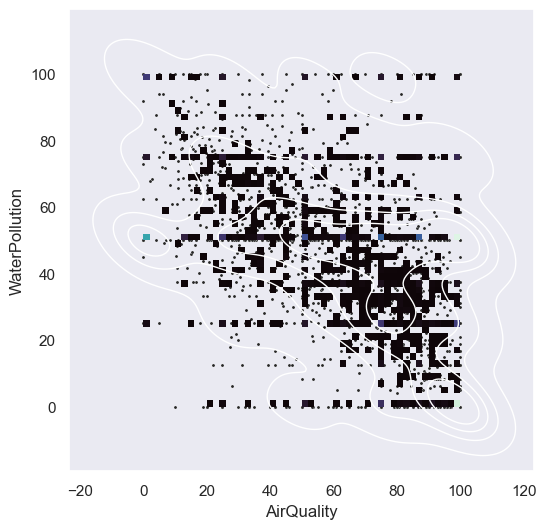

In [82]:
f, ax = plt.subplots(figsize=(6, 6))
sns.scatterplot(x=x, y=y, s=5, color=".15")
sns.histplot(x=x, y=y, bins=50, pthresh=.1, cmap="mako")
sns.kdeplot(x=x, y=y, levels=5, color="w", linewidths=1)

# qayta tartiblash

In [85]:
df3

Object                       AIR                       Water             
Info                  AirQuality WaterPollution AirPollution waterquality
Country     City                                                         
Afghanistan Andkhoy    50.000000      50.000000    50.000000    50.000000
            Farah     100.000000       0.000000     0.000000   100.000000
            Herat      43.750000      31.250000    56.250000    68.750000
            Kabul      18.421053      81.060606    81.578947    18.939394
            Kandahar    0.000000      75.000000   100.000000    25.000000
...                          ...            ...          ...          ...
Zambia      Mansa      75.000000      25.000000    25.000000    75.000000
Zimbabwe    Bindura    50.000000      75.000000    50.000000    25.000000
            Bulawayo   67.857143      71.428571    32.142857    28.571429
            Harare     38.461538      87.500000    61.538462    12.500000
            Masvingo   25.000000      62.500000    75.000000    37.500000

[3895 rows x 4 columns]

# swaplevel

In [86]:
df3.swaplevel('Country', 'City') # bu bizga irarxik indekslarimizni o'rnini almashtiradi 

Object                       AIR                       Water             
Info                  AirQuality WaterPollution AirPollution waterquality
City     Country                                                         
Andkhoy  Afghanistan   50.000000      50.000000    50.000000    50.000000
Farah    Afghanistan  100.000000       0.000000     0.000000   100.000000
Herat    Afghanistan   43.750000      31.250000    56.250000    68.750000
Kabul    Afghanistan   18.421053      81.060606    81.578947    18.939394
Kandahar Afghanistan    0.000000      75.000000   100.000000    25.000000
...                          ...            ...          ...          ...
Mansa    Zambia        75.000000      25.000000    25.000000    75.000000
Bindura  Zimbabwe      50.000000      75.000000    50.000000    25.000000
Bulawayo Zimbabwe      67.857143      71.428571    32.142857    28.571429
Harare   Zimbabwe      38.461538      87.500000    61.538462    12.500000
Masvingo Zimbabwe      25.000000      62.500000    75.000000    37.500000

[3895 rows x 4 columns]

# mana ko'rib turganinggizdek country va city joyi almashdi avval esa teskari turgandi

# sort_indek

* level 0 df3 ni asil holiga qaytarati yani country city korinishiga

* askending usish tartibida sort lash degani biz hozir teskarisini qilmoqdamiz

In [87]:
df3.sort_index(level=0, ascending=False)

Object                       AIR                       Water             
Info                  AirQuality WaterPollution AirPollution waterquality
Country     City                                                         
Zimbabwe    Masvingo   25.000000      62.500000    75.000000    37.500000
            Harare     38.461538      87.500000    61.538462    12.500000
            Bulawayo   67.857143      71.428571    32.142857    28.571429
            Bindura    50.000000      75.000000    50.000000    25.000000
Zambia      Mansa      75.000000      25.000000    25.000000    75.000000
...                          ...            ...          ...          ...
Afghanistan Kandahar    0.000000      75.000000   100.000000    25.000000
            Kabul      18.421053      81.060606    81.578947    18.939394
            Herat      43.750000      31.250000    56.250000    68.750000
            Farah     100.000000       0.000000     0.000000   100.000000
            Andkhoy    50.000000      50.000000    50.000000    50.000000

[3895 rows x 4 columns]

# endi malumotlarimiz asil holatiga qaytdi va teskari tartibga utdi

* the end